In [1]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf, get_window

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)

In [2]:
wandb_id = 'rv6m9iyn'
device = 'cuda'

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()

# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [3]:
tmp = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv')

In [4]:
forestloss_dir = '../../Vancutsem_yearloss'
tmf_extent = get_tiles_as_gdf(forestloss_dir)
tmf_extent.crs = 4326


# Load a land mask (for simplicity, this can be a GeoDataFrame of the world land mask)
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# Filter world data to only include land areas
land_areas = gpd.overlay(world, tmf_extent, how='intersection')

/tmp/ipykernel_157981/1446822280.py:7: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_157981/1446822280.py:9: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  land_areas = gpd.overlay(world, tmf_extent, how='intersection')


In [86]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()
    
def plot_images_with_tmf(data, tmf, label, figsize=(16,16)):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(figsize[0], figsize[1]))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.17

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    im = ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    fig.colorbar(im, ax=ax[n_images], fraction=0.046, pad=0.04)
    
    fig.tight_layout()
    plt.show()
    



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


mining


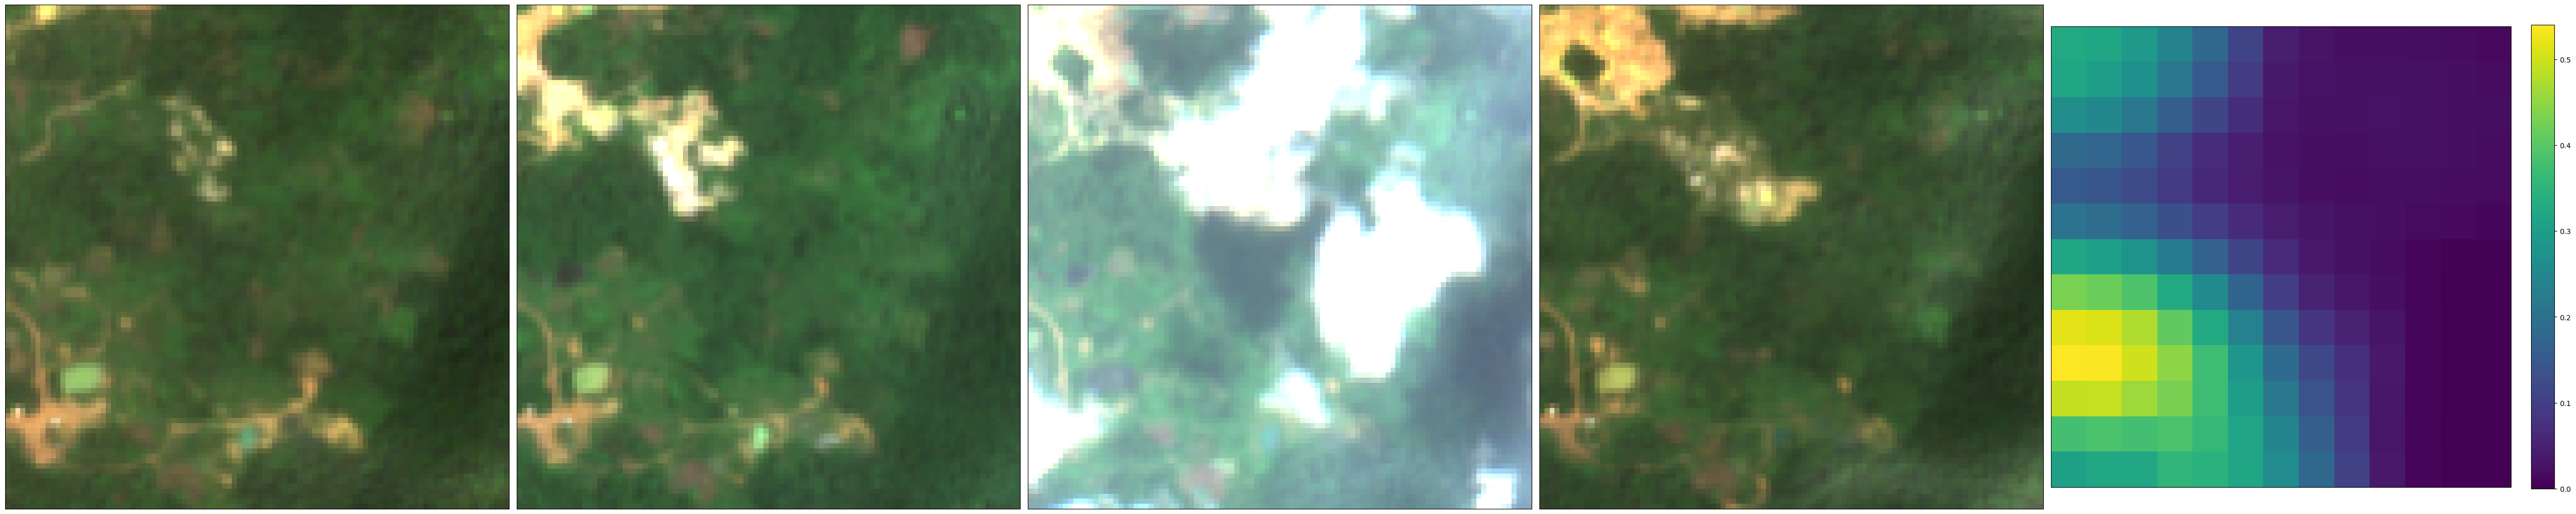

In [87]:
plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label], figsize=(50,15))

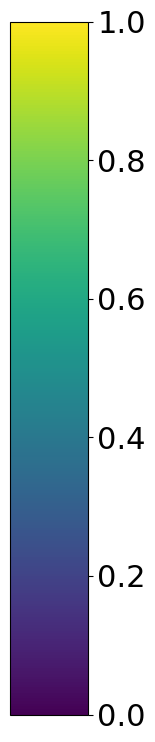

In [99]:
import matplotlib.pyplot as plt

# Standalone vertical colorbar from 0 to 1 with larger font
fig, ax = plt.subplots(figsize=(1, 9))
norm = plt.Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(norm=norm, cmap='viridis')
sm.set_array([])  # for compatibility

cb = plt.colorbar(
    sm,
    cax=ax,
    orientation='vertical'
)

# Increase font size for ticks and label
cb.ax.tick_params(labelsize=22)
#cb.set_label('Value', fontsize=16)

plt.show()


In [ ]:

def is_correct(predictions: dict, ground_truth: str) -> bool:
    return max(predictions, key=predictions.get) == ground_truth


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


driver                                            mining
sampleid                                       140030677
dataset                                        mines.csv
country                                            Ghana
geometry    POINT (-0.601553076627396 6.248435582054672)
block_id                                           147.0
split                                                val
dst_size                                             NaN
Name: 1247, dtype: object
{'cocoa': 2.24,
 'coffee': 0.0,
 'forest plantation': 0.0,
 'mining': nan,
 'other': nan,
 'palm oil': 0.02,
 'pasture': 0.82,
 'rubber': 0.12,
 'shifting agriculture': nan,
 'soy': 0.09,
 'urban': nan}

{'cocoa': 0.412,
 'coffee': 0.001,
 'forest plantation': 0.0,
 'mining': 0.138,
 'other': 0.005,
 'palm oil': 0.013,
 'pasture': 0.001,
 'rubber': 0.0,
 'shifting agriculture': 0.361,
 'soy': 0.0,
 'urban': 0.068}
mining


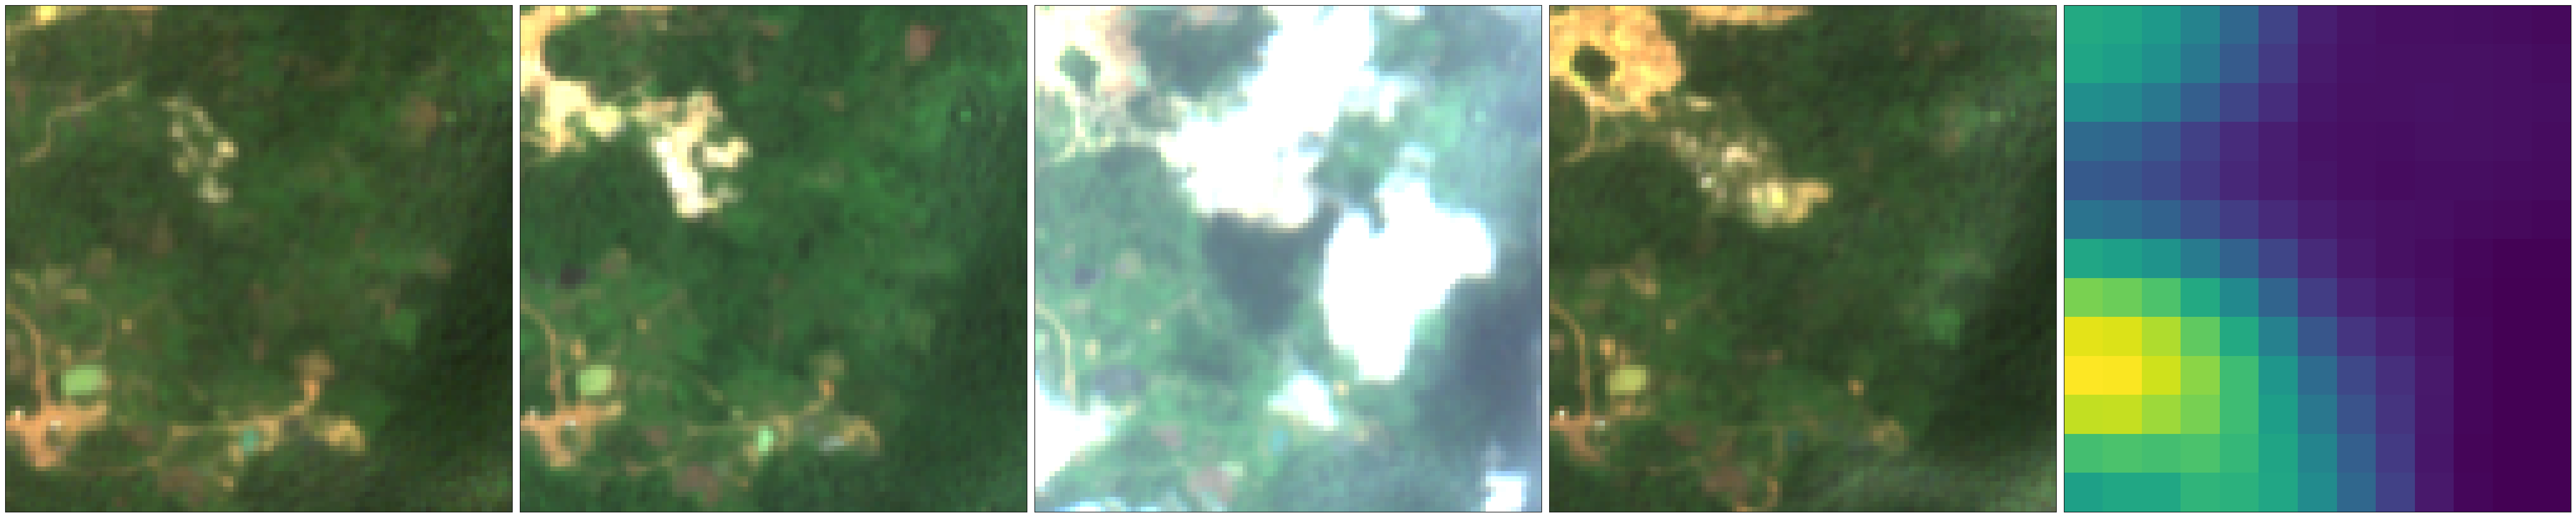

KeyboardInterrupt: Interrupted by user

In [71]:
while True:
    row = val_dl.dataset.img_labels.sample(1).iloc[0]
    if row.driver == 'pasture':
        continue
    if row.country ==  'Viet Nam' or row.country == "Brazil":
        continue
    #if row.driver in ['coffee', 'soy', 'rubber', 'pasture', 'mining', 'palm oil','cocoa' ]:
    #    continue
        
    idx = row.name

    
    x, label = val_dl.dataset.__getitem__(idx)
    ts, loc, expansion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    
    if is_correct(preds, inverse_label_mapping[label]):
        continue
    
    print(row)
    pprint.pprint(rates)
    print()
    pprint.pprint(preds)

        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label], figsize=(50,15))

    _waitforinput = input()

    clear_output(wait=True)

'cocoa'

In [17]:
is_correct(preds, inverse_label_mapping[label])

True

In [15]:
preds

{'pasture': 0.0,
 'forest plantation': 0.0,
 'soy': 0.0,
 'coffee': 0.0,
 'palm oil': 0.001,
 'mining': 0.0,
 'urban': 0.0,
 'cocoa': 0.997,
 'rubber': 0.0,
 'shifting agriculture': 0.001,
 'other': 0.0}

In [16]:
max(preds, key=preds.get)

'cocoa'

In [ ]:

## examples
# sampleid 10035846
# correct, Brazil, pasture

# 20015808
# incorrect, Vietnam, rubber (predicted coffee)

#80075778
#incorrect, Indonesia, forest planation (predicted palm oil)

# 90042876
#correct, Costa Rica, palm oil

In [ ]:
#150028828 incorrect soy

In [76]:


sampleids = {
    10035846 : {},
    20015808 : {},
    80075778 : {},
    90042876 : {},
    140030677 : {}
}

In [77]:


for sampleid in sampleids.keys():
     
    row = val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == sampleid].iloc[0]

    idx = row.name

    
    x, label = val_dl.dataset.__getitem__(idx)
    ts, loc, expansion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]

    
    sampleids[sampleid]['ts'] = ts
    sampleids[sampleid]['forestloss'] = forestloss
    sampleids[sampleid]['tabular'] = rates
    sampleids[sampleid]['loc'] = _loc
    sampleids[sampleid]['preds'] = preds
    sampleids[sampleid]['label'] = inverse_label_mapping[label]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


pasture


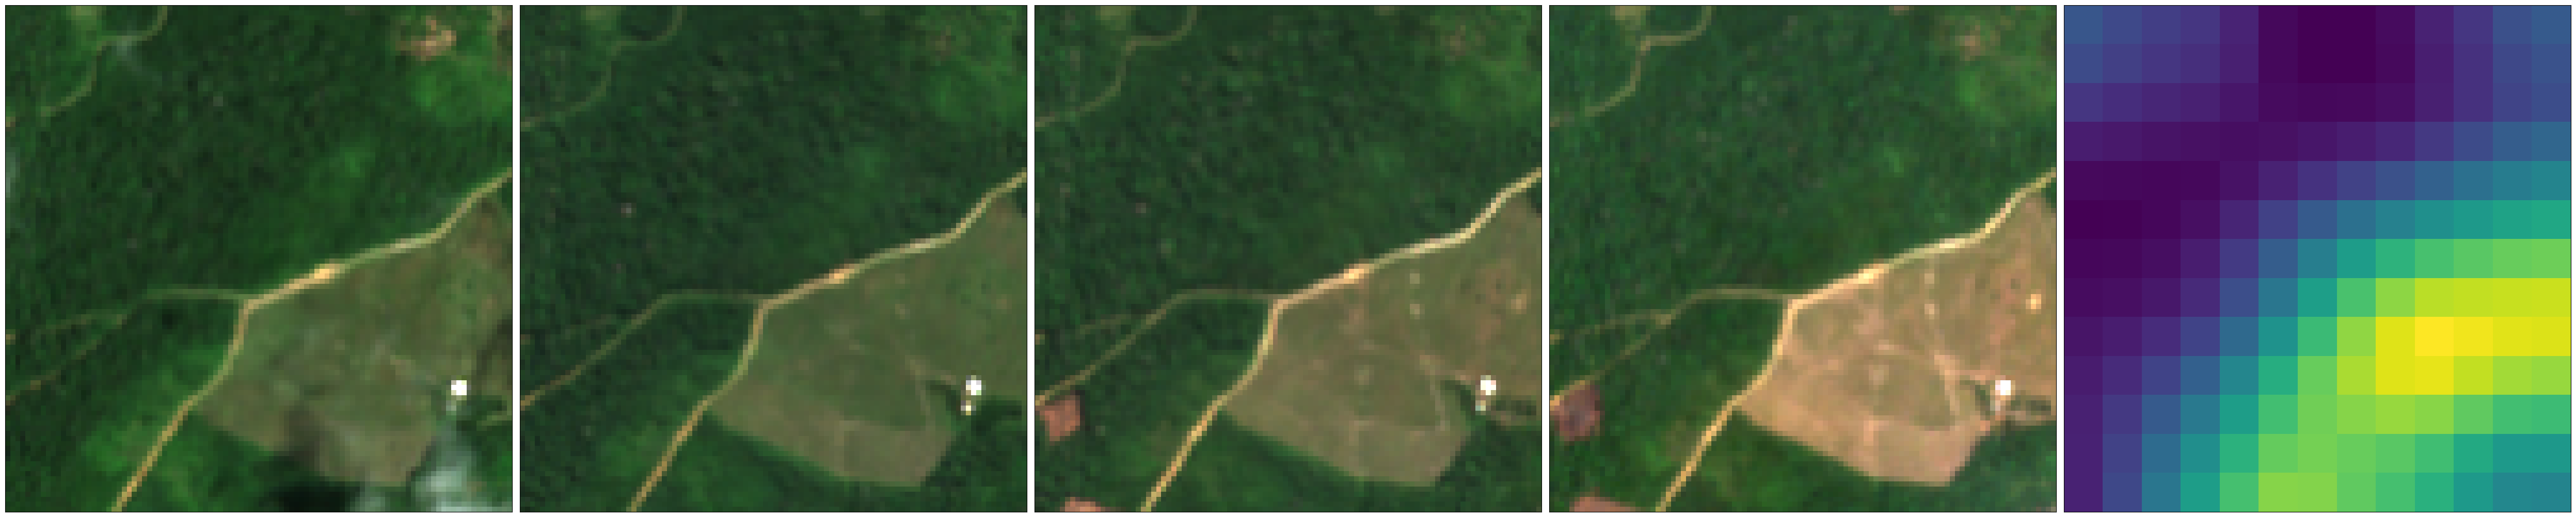

In [41]:



plot_images_with_tmf(sampleids[10035846]['ts'], sampleids[10035846]['forestloss'], label=sampleids[10035846]['label'], figsize=(50,15))


In [62]:
sampleids[10035846]['preds']

{'pasture': 0.987,
 'forest plantation': 0.004,
 'soy': 0.002,
 'coffee': 0.001,
 'palm oil': 0.002,
 'mining': 0.0,
 'urban': 0.0,
 'cocoa': 0.001,
 'rubber': 0.0,
 'shifting agriculture': 0.0,
 'other': 0.002}

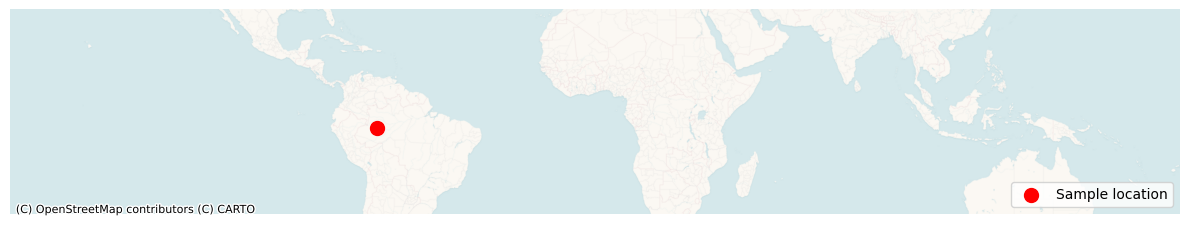

In [60]:
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point
from pyproj import Transformer

# Input coordinates
lat, lon = sampleids[10035846]['loc'][0].cpu().numpy()

# Define tropical belt bounds
LAT_MIN, LAT_MAX = -30, 30
LON_MIN, LON_MAX = -180, 180  # full longitude span

# Project geographic bounds to Web Mercator (EPSG:3857)
transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
x_min, y_min = transformer.transform(LON_MIN, LAT_MIN)
x_max, y_max = transformer.transform(LON_MAX, LAT_MAX)

# Create a GeoDataFrame for the point and project it
point_gdf = (
    gpd.GeoDataFrame(
        {"geometry": [Point(lon, lat)]},
        crs="EPSG:4326"
    )
    .to_crs(epsg=3857)
)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

# Plot the point
point_gdf.plot(ax=ax, marker="o", color="red", markersize=100, label="Sample location")

# Add basemap
ctx.add_basemap(
    ax,
    source=ctx.providers.CartoDB.VoyagerNoLabels,
    crs=point_gdf.crs.to_string(),
    zoom=4
)

# Clean up
ax.set_axis_off()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


forest plantation


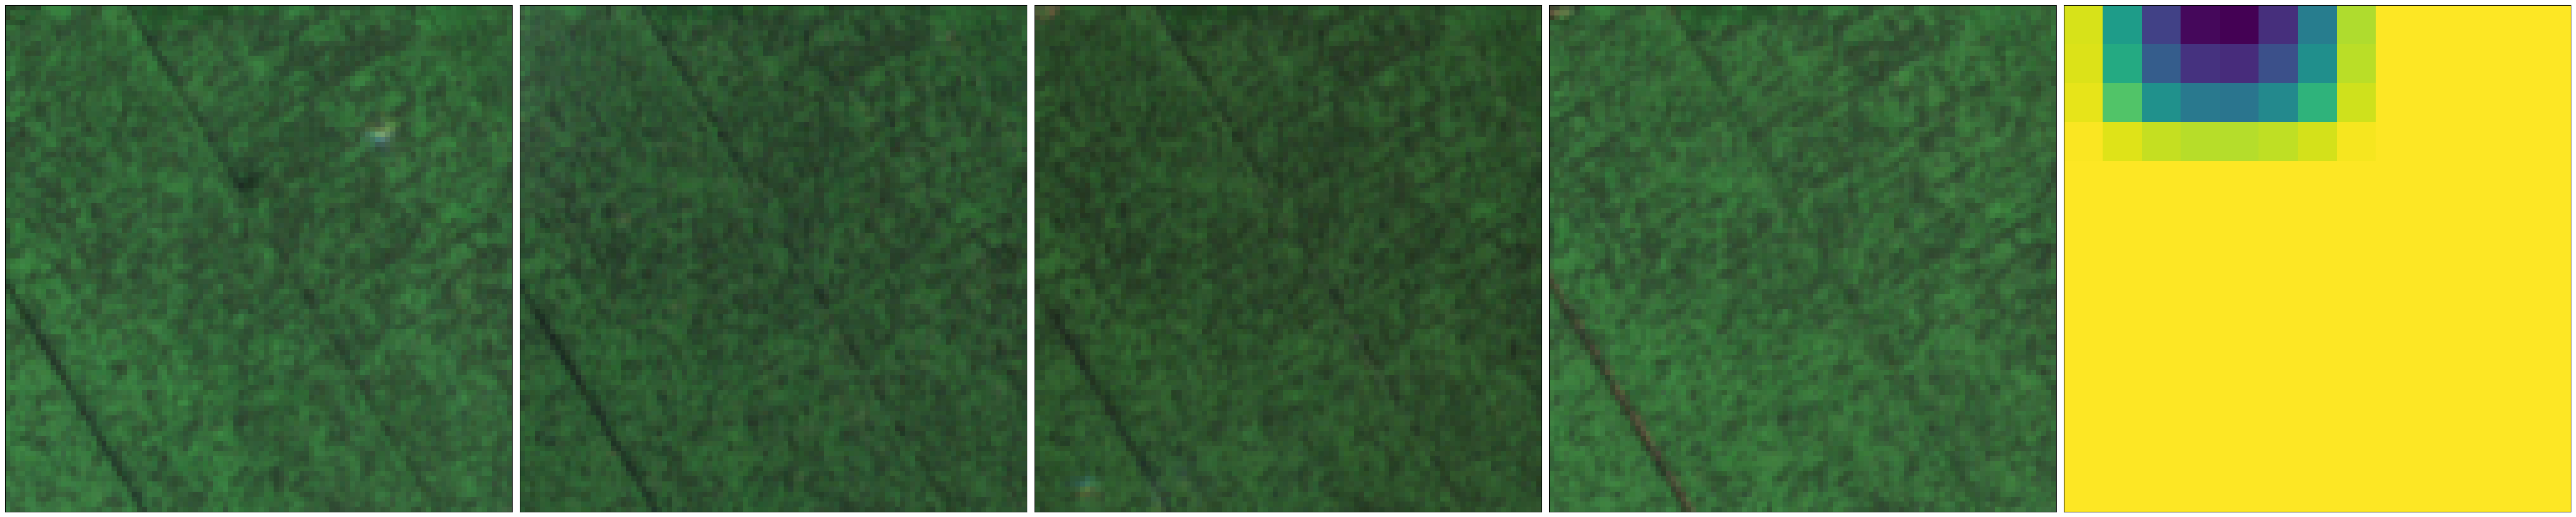

In [67]:

140030677

plot_images_with_tmf(sampleids[80075778]['ts'], sampleids[80075778]['forestloss'], label=sampleids[80075778]['label'], figsize=(50,15))


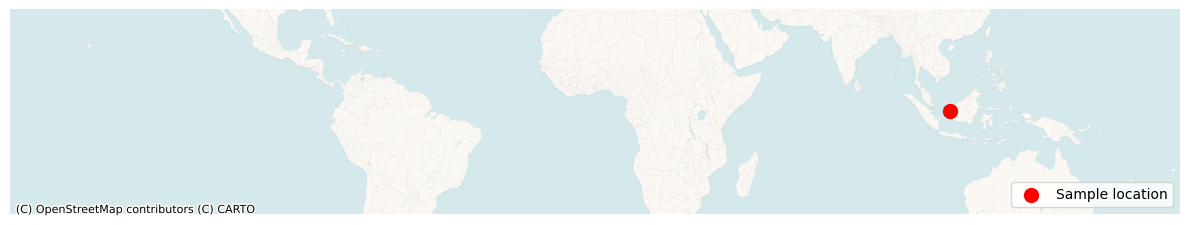

In [68]:
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point
from pyproj import Transformer

# Input coordinates
lat, lon = sampleids[80075778]['loc'][0].cpu().numpy()

# Define tropical belt bounds
LAT_MIN, LAT_MAX = -30, 30
LON_MIN, LON_MAX = -180, 180  # full longitude span

# Project geographic bounds to Web Mercator (EPSG:3857)
transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
x_min, y_min = transformer.transform(LON_MIN, LAT_MIN)
x_max, y_max = transformer.transform(LON_MAX, LAT_MAX)

# Create a GeoDataFrame for the point and project it
point_gdf = (
    gpd.GeoDataFrame(
        {"geometry": [Point(lon, lat)]},
        crs="EPSG:4326"
    )
    .to_crs(epsg=3857)
)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

# Plot the point
point_gdf.plot(ax=ax, marker="o", color="red", markersize=100, label="Sample location")

# Add basemap
ctx.add_basemap(
    ax,
    source=ctx.providers.CartoDB.VoyagerNoLabels,
    crs=point_gdf.crs.to_string(),
    zoom=4
)

# Clean up
ax.set_axis_off()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [70]:
sampleids[80075778]['preds']

{'pasture': 0.002,
 'forest plantation': 0.282,
 'soy': 0.0,
 'coffee': 0.0,
 'palm oil': 0.372,
 'mining': 0.009,
 'urban': 0.0,
 'cocoa': 0.002,
 'rubber': 0.33,
 'shifting agriculture': 0.0,
 'other': 0.002}

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


mining


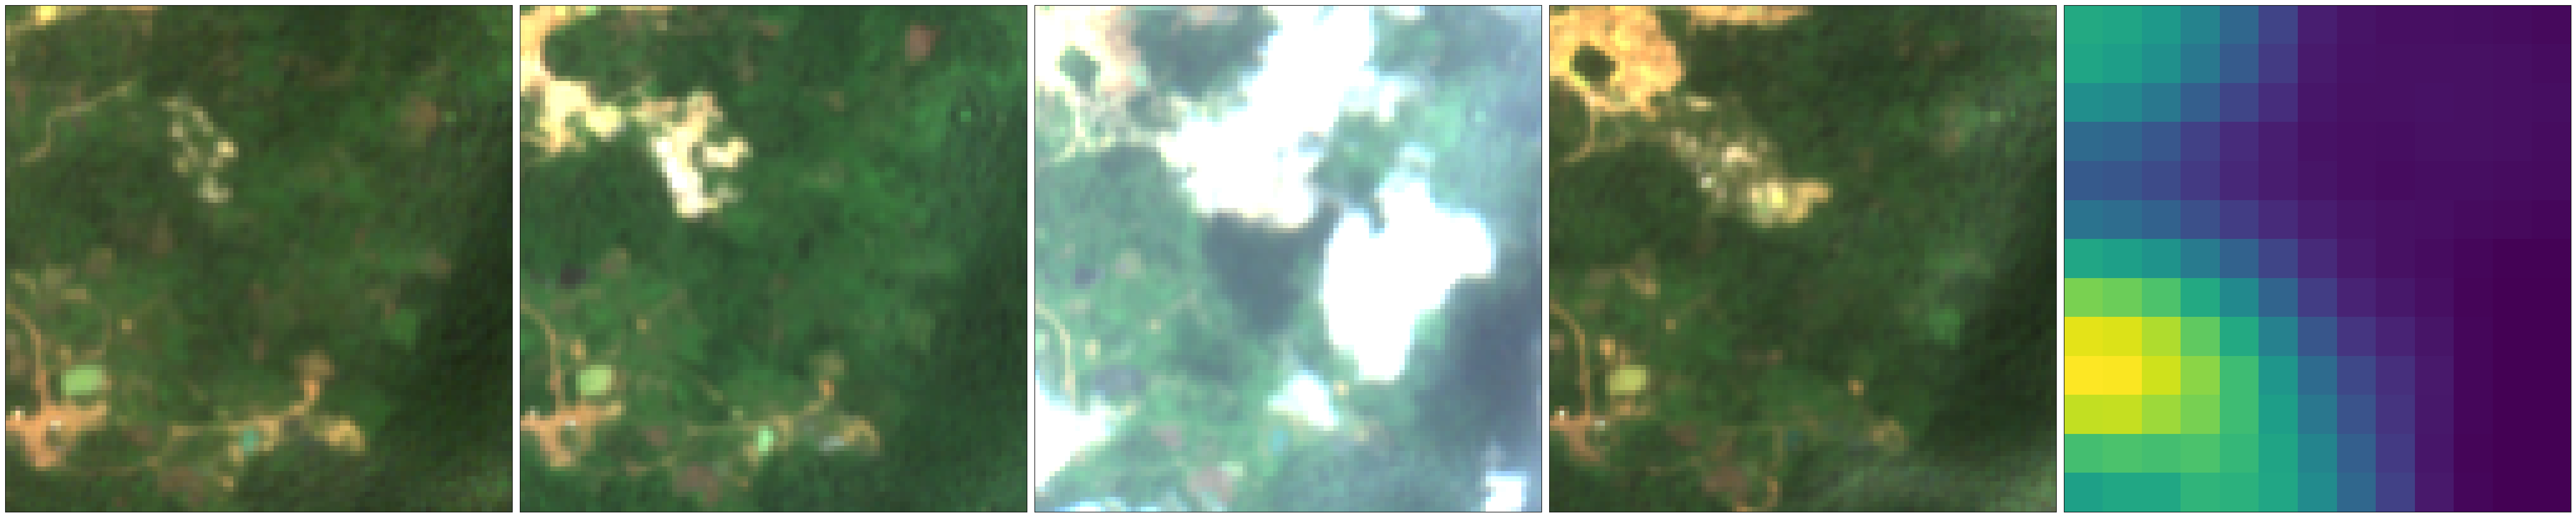

In [78]:


plot_images_with_tmf(sampleids[140030677]['ts'], sampleids[140030677]['forestloss'], label=sampleids[140030677]['label'], figsize=(50,15))


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


palm oil


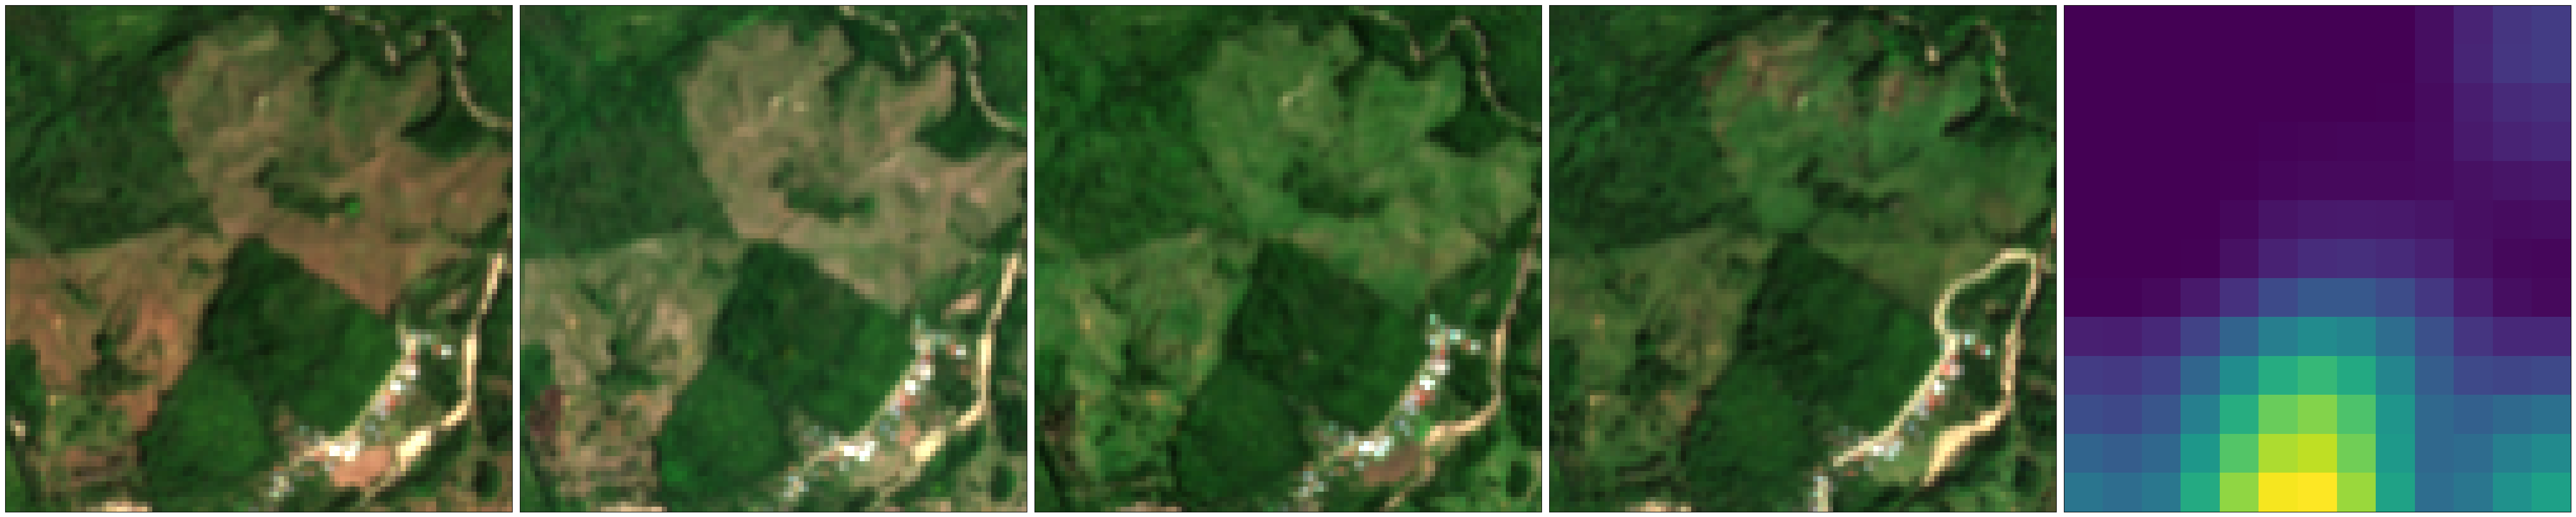

In [79]:



plot_images_with_tmf(sampleids[90042876]['ts'], sampleids[90042876]['forestloss'], label=sampleids[90042876]['label'], figsize=(50,15))


In [82]:
sampleids[90042876]['preds']

{'pasture': 0.004,
 'forest plantation': 0.0,
 'soy': 0.0,
 'coffee': 0.001,
 'palm oil': 0.51,
 'mining': 0.019,
 'urban': 0.001,
 'cocoa': 0.436,
 'rubber': 0.008,
 'shifting agriculture': 0.02,
 'other': 0.0}

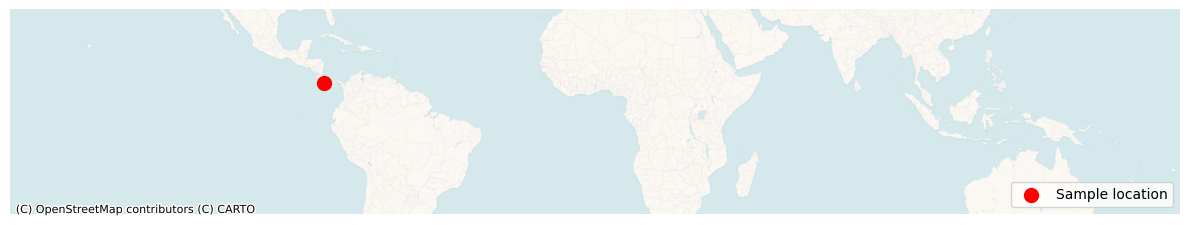

In [83]:
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point
from pyproj import Transformer

# Input coordinates
lat, lon = sampleids[90042876]['loc'][0].cpu().numpy()

# Define tropical belt bounds
LAT_MIN, LAT_MAX = -30, 30
LON_MIN, LON_MAX = -180, 180  # full longitude span

# Project geographic bounds to Web Mercator (EPSG:3857)
transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
x_min, y_min = transformer.transform(LON_MIN, LAT_MIN)
x_max, y_max = transformer.transform(LON_MAX, LAT_MAX)

# Create a GeoDataFrame for the point and project it
point_gdf = (
    gpd.GeoDataFrame(
        {"geometry": [Point(lon, lat)]},
        crs="EPSG:4326"
    )
    .to_crs(epsg=3857)
)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

# Plot the point
point_gdf.plot(ax=ax, marker="o", color="red", markersize=100, label="Sample location")

# Add basemap
ctx.add_basemap(
    ax,
    source=ctx.providers.CartoDB.VoyagerNoLabels,
    crs=point_gdf.crs.to_string(),
    zoom=4
)

# Clean up
ax.set_axis_off()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [56]:
ctx.providers.CartoDB

{'Positron': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'light_all',
  'name': 'CartoDB.Positron'},
 'PositronNoLabels': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'light_nolabels',
  'name': 'CartoDB.PositronNoLabels'},
 'PositronOnlyLabels': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'light_only_labels',
  'name': 'CartoDB.PositronOnlyLabels'},
 'DarkMatter': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'dark_all',
  'name': 'CartoDB.DarkMatter'},
 'DarkMatterNoLabels': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'dark_nolabels',
  'name': 'CartoDB.DarkMatterNoLabels'},
 'DarkMatterOnlyLabels': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'dark_only_labels',
  'name': 'CartoDB.DarkMatterOnlyLabels'},
 'Voyager': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'rastertiles/voyager',
  'name': 'CartoDB.Voyager'},
 'VoyagerNoLabels': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'rastertiles/voyager_nolabels',
  'name': 'CartoDB.VoyagerNoLabels'},
 'VoyagerOnlyLabels': {'url': 'https://{s}.basemaps.cartocdn.com/{variant}/{z}/{x}/{y}{r}.png',
  'html_attribution': '&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
  'attribution': '(C) OpenStreetMap contributors (C) CARTO',
  'subdomains': 'abcd',
  'max_zoom': 20,
  'variant': 'rastertiles/voyager_only_labels',
  'name': 'CartoDB.VoyagerOnlyLabels'},
 'VoyagerLabelsUnder': {'url': 'https://{s}.basema

In [50]:
# Modify class names to show two-word names on two lines
formatted_header_row = ["Class name"] + [
    k.replace(" ", "<br>") for k in data.keys()
]

# Format as Markdown table with line breaks
markdown_table = "| " + " | ".join(formatted_header_row) + " |\n"
markdown_table += "| " + " | ".join(["---"] * len(formatted_header_row)) + " |\n"
markdown_table += "| " + " | ".join(value_row) + " |"

display(Markdown(markdown_table))


| Class name | pasture | forest<br>plantation | soy | coffee | palm<br>oil | mining | urban | cocoa | rubber | shifting<br>agriculture | other |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Tabular value | 1.82 | 0.03 | 0.37 | 0.01 | 0.00 | - | - | 0.00 | 0.00 | - | - |

0